# Explore HTRU1 Batch 1

Quick look at one training batch from the HTRU1 dataset: shape, labels, class balance, and the three diagnostic image channels across several labeled candidates.

No model training in this notebook.

## Imports

In [19]:
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

## Load one batch

HTRU1 batches are CIFAR-style pickle files. We load `data_batch_1` with `encoding="latin1"` for Python 3 compatibility.

In [20]:
batch_path = Path("../data/raw/htru1-batches-py/data_batch_1")

with open(batch_path, "rb") as f:
    batch = pickle.load(f, encoding="latin1")

data = np.asarray(batch["data"])
labels = np.asarray(batch["labels"])
filenames = batch["filenames"]

## Batch summary

According to `batches.meta`, label **0 = pulsar** and label **1 = nonpulsar**.

In [21]:
print("Available batch keys:", list(batch.keys()))
print("Full data shape:", data.shape)
print("Labels shape:", labels.shape)
print("Data type:", data.dtype)
print("Min / max values:", data.min(), data.max())

n_pulsar = np.sum(labels == 0)
n_nonpulsar = np.sum(labels == 1)

print(f"Pulsar count (label 0): {n_pulsar}")
print(f"Non-pulsar count (label 1): {n_nonpulsar}")

Available batch keys: ['data', 'labels', 'batch_label', 'filenames']
Full data shape: (10000, 3072)
Labels shape: (10000,)
Data type: uint8
Min / max values: 24 229
Pulsar count (label 0): 199
Non-pulsar count (label 1): 9801


## Why each candidate has 3072 values

Each candidate is stored as a flat vector of length **3072**. That comes from three diagnostic channels, each a 32 × 32 image:

$$
3 \times 32 \times 32 = 3072
$$

The channels are packed channel-first in the flat vector, matching a reshape to `(3, 32, 32)`.

## Compare multiple labeled candidates

Individual compressed candidates may not be visually obvious: a single 32 × 32 diagnostic plot is often hard to interpret by eye. A CNN is useful here because it can learn statistical patterns across many labeled examples, rather than relying on one striking image.

Below we randomly sample 5 pulsars and 5 non-pulsars (fixed seed) and plot each diagnostic channel in its own figure.

In [22]:
rng = np.random.default_rng(42)

pulsar_indices = rng.choice(
    np.where(labels == 0)[0],
    size=5,
    replace=False,
)

nonpulsar_indices = rng.choice(
    np.where(labels == 1)[0],
    size=5,
    replace=False,
)

print("Pulsar indices:", pulsar_indices)
print("Non-pulsar indices:", nonpulsar_indices)

Pulsar indices: [151  86 128  17 198]
Non-pulsar indices: [9759 1121 5357 7658 7409]


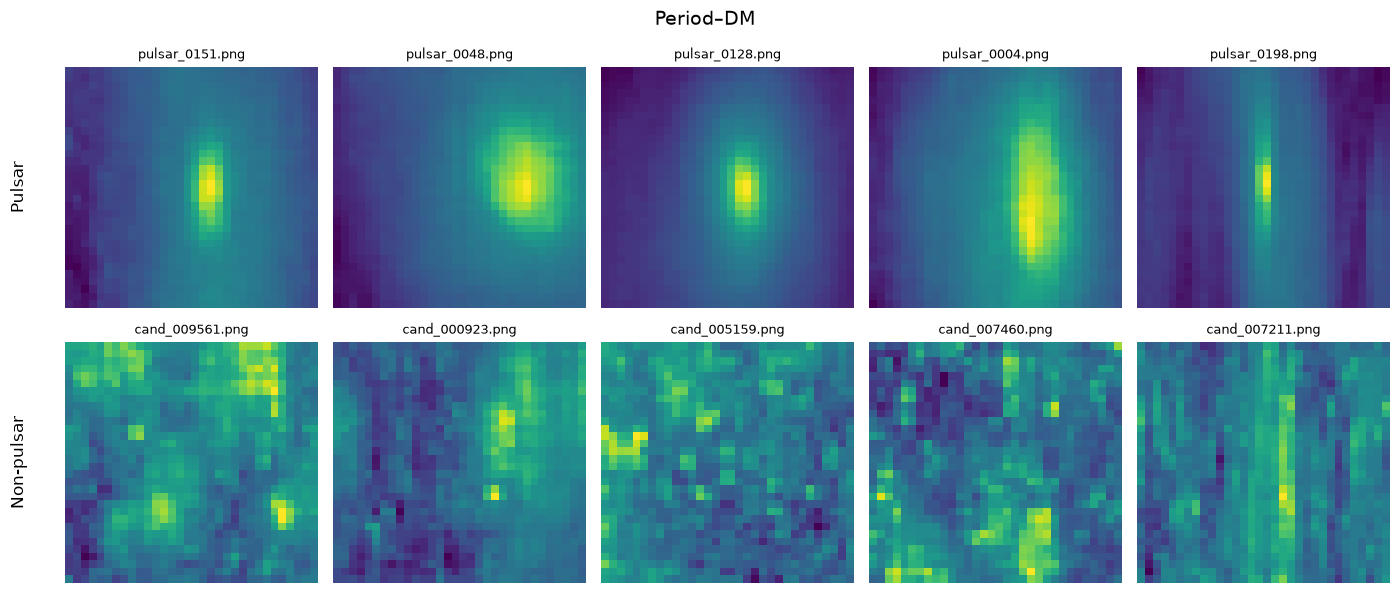

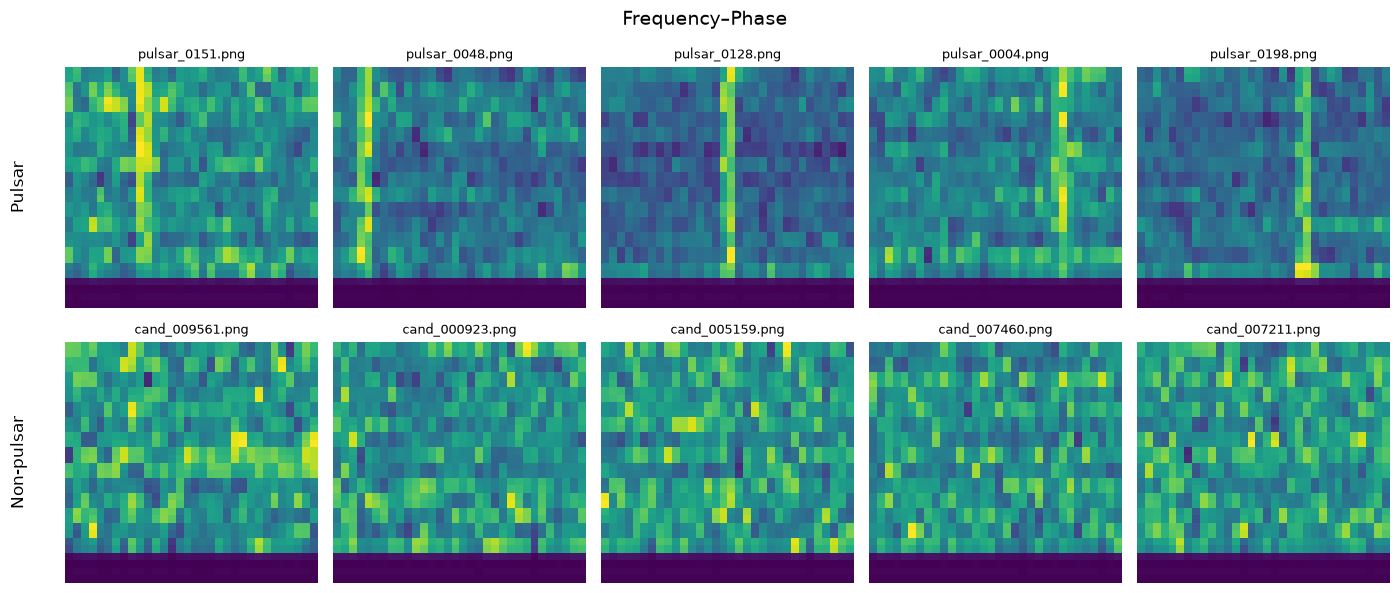

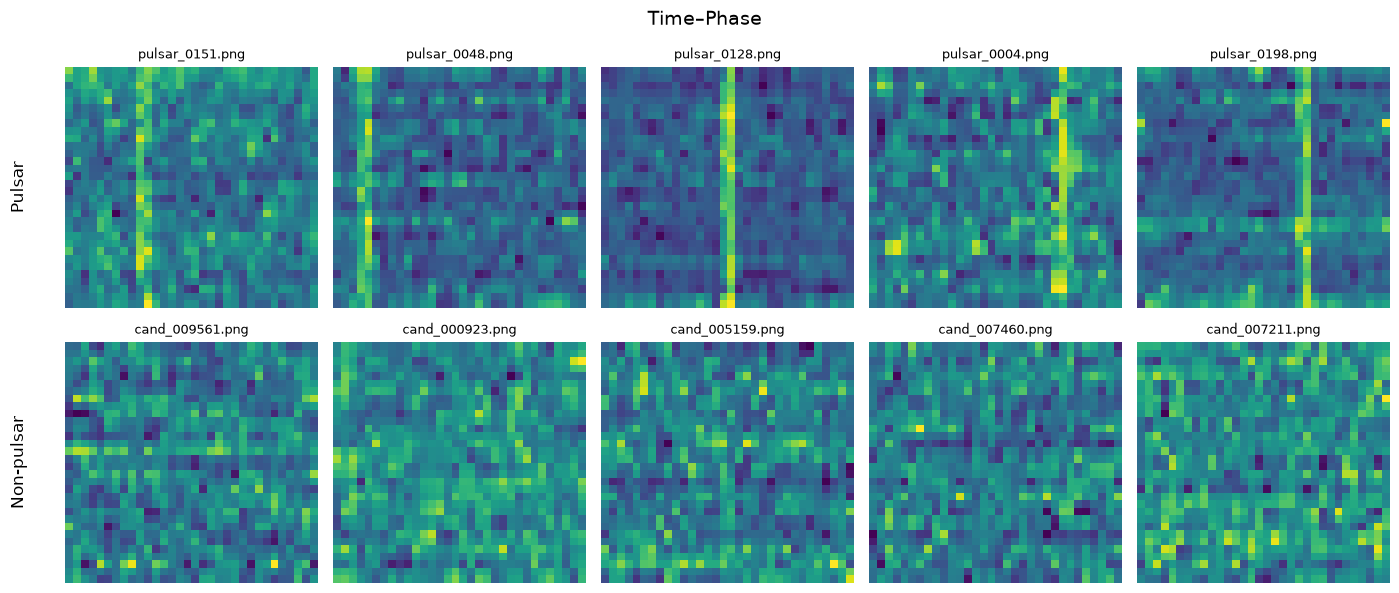

In [23]:
channel_titles = [
    "Period–DM",
    "Frequency–Phase",
    "Time–Phase",
]


def short_filename(name):
    if isinstance(name, bytes):
        name = name.decode("latin1")
    return Path(name).name


def plot_channel_grid(channel_idx, channel_title):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))

    for col, idx in enumerate(pulsar_indices):
        img = data[idx].reshape(3, 32, 32)
        axes[0, col].imshow(
            img[channel_idx],
            cmap="viridis",
            origin="lower",
            aspect="auto",
            interpolation="nearest",
        )
        axes[0, col].set_title(short_filename(filenames[idx]), fontsize=9)
        axes[0, col].axis("off")

    for col, idx in enumerate(nonpulsar_indices):
        img = data[idx].reshape(3, 32, 32)
        axes[1, col].imshow(
            img[channel_idx],
            cmap="viridis",
            origin="lower",
            aspect="auto",
            interpolation="nearest",
        )
        axes[1, col].set_title(short_filename(filenames[idx]), fontsize=9)
        axes[1, col].axis("off")

    axes[0, 0].text(
        -0.15,
        0.5,
        "Pulsar",
        transform=axes[0, 0].transAxes,
        rotation=90,
        va="center",
        ha="right",
        fontsize=12,
    )
    axes[1, 0].text(
        -0.15,
        0.5,
        "Non-pulsar",
        transform=axes[1, 0].transAxes,
        rotation=90,
        va="center",
        ha="right",
        fontsize=12,
    )

    fig.suptitle(channel_title, fontsize=14)
    fig.tight_layout()
    plt.show()


for channel_idx, channel_title in enumerate(channel_titles):
    plot_channel_grid(channel_idx, channel_title)

## Takeaways

- One batch holds 10,000 candidates, each a 3072-length uint8 vector.
- Labels are imbalanced: few pulsars relative to non-pulsars.
- Single candidates are often hard to classify by eye; a CNN can learn patterns from many labeled examples.
- Training is left for a later notebook.

In [24]:
print("Data shape:", data.shape)
print("Labels shape:", labels.shape)
print("Data type:", data.dtype)
print("Minimum:", data.min())
print("Maximum:", data.max())
print("Unique labels:", np.unique(labels, return_counts=True))

Data shape: (10000, 3072)
Labels shape: (10000,)
Data type: uint8
Minimum: 24
Maximum: 229
Unique labels: (array([0, 1]), array([ 199, 9801]))
